# Projecting bulk ATAC-seq into a single-cell embedding

Bulk ATAC-seq of sorted populations is the classic reference for what a cell type's chromatin looks like. `epi.tl.project_bulk_atac` places such bulk profiles onto a single-cell embedding, which shows where each sorted population falls among the single cells. It is a port of ArchR's `projectBulkATAC` (Granja *et al.*, *Nat Genet* 2021):

1. Each bulk sample is down-sampled into 250 pseudo-cells: its reads are sampled with replacement at 2, 1.5, 1, 0.5 and 0.25 times the mean single-cell depth.
2. The pseudo-cells are projected into the single-cell LSI space with the stored LSI model.
3. From there they are projected into the UMAP.

`epi.tl.deconvolve_bulk` asks the reverse question: which mixture of single-cell clusters best explains each bulk profile? It fits non-negative least squares on cluster pseudobulk profiles.

**Data.**
- Single cells: the hematopoiesis scATAC-seq data built in [the ArchR hematopoiesis tutorial](t_archr_heme_data.ipynb). Run that notebook first; this one reads its cache from `EPIONE_ARCHR_HEME`.
- Bulk: Corces *et al.* 2016 (GEO GSE74912), ATAC-seq of 13 sorted normal hematopoietic populations from 9 donors, 77 samples, hg19. It is downloaded by `epi.datasets.corces2016_bulk_atac`.

In [1]:
%matplotlib inline
import os
import pathlib
import time

import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt

import epione as epi

epi.pl.plot_set()
DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))
CACHE = DATA / 'cache'

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Single-cell data and its LSI model

Projection needs the LSI *model*, not just the embedding: the IDF denominators of the fitted cells, the loadings and the dimension scaling. `iterative_lsi` stores these in `uns['X_iterative_lsi']`. The tile matrix cached by the hematopoiesis tutorial predates that, so we re-run `iterative_lsi` with the same parameters. It is deterministic, and the check below confirms that the embedding is unchanged. Clusters and UMAP come from the same tutorial's cell table.

In [2]:
%%time
tiles = ad.read_h5ad(CACHE / 'tiles_lsi.h5ad')
cells = pd.read_csv(DATA / 'heme_cells.tsv', sep='\t', index_col=0).loc[tiles.obs_names]

old = tiles.obsm['X_iterative_lsi'].copy()
epi.tl.iterative_lsi(
    tiles, n_components=30, iterations=2, var_features=25_000,
    resolution=2.0, n_neighbors=20, sample_cells_pre=10_000,
    depth_col='n_fragment', seed=1, verbose=False,
)
print('embedding unchanged:', np.array_equal(old, tiles.obsm['X_iterative_lsi']))

tiles.obs['Clusters'] = pd.Categorical(
    cells['Clusters'], categories=[f'C{i}' for i in range(1, 12)])
tiles.obsm['X_umap'] = cells[['UMAP1', 'UMAP2']].to_numpy()
# the UMAP settings of the hematopoiesis tutorial
tiles.uns['neighbors'] = {'params': {'n_neighbors': 30, 'metric': 'cosine'}}
tiles.uns['umap'] = {'params': {'min_dist': 0.5}}
print(tiles)

computing neighbors


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:33)


running Leiden clustering


    finished: found 19 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


embedding unchanged: True
AnnData object with n_obs × n_vars = 10705 × 6274368
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'Sample', 'tss_score', 'tsse', 'log10_nFrags', 'Clusters'
    uns: 'X_iterative_lsi', 'files', 'library_tsse', 'reference_sequences', 'neighbors', 'umap'
    obsm: 'X_iterative_lsi', 'X_umap'
    varm: 'X_iterative_lsi_loadings'
CPU times: user 1min 17s, sys: 4.67 s, total: 1min 21s
Wall time: 1min 34s


## Bulk ATAC-seq of sorted populations

In [3]:
bulk = epi.datasets.corces2016_bulk_atac(DATA / 'corces2016')
print(bulk)
bulk.obs['cell_type'].value_counts().reindex(bulk.obs['cell_type'].cat.categories).to_frame('samples').T

AnnData object with n_obs × n_vars = 77 × 590650
    obs: 'cell_type', 'donor'
    var: 'chrom', 'start', 'end'


,HSC,MPP,LMPP,CMP,GMP,MEP,Ery,Mono,CLP,B,CD4T,CD8T,NK
samples,7,6,3,8,7,7,8,6,5,4,5,5,6


## Projection

The bulk peaks are mapped onto the LSI features, here 500 bp tiles, as in ArchR: each feature takes the counts of the overlapping bulk peak with the most reads. `groupby` also labels each pseudo-cell with the majority cluster of its 10 nearest single cells in LSI space.

The UMAP from scanpy keeps no model to project into, so `project_bulk_atac` fits a `umap-learn` model on the same LSI, initialised from the existing layout. The single cells' coordinates under that model are returned in `uns['reference_umap']`. Plot pseudo-cells against those, not against the original layout. The re-projection correlation checks that the model reproduces the layout.

In [4]:
%%time
proj = epi.tl.project_bulk_atac(tiles, bulk, groupby='Clusters', seed=1, verbose=False)
proj.obs['cell_type'] = pd.Categorical(
    bulk.obs.loc[proj.obs['sample'].astype(str), 'cell_type'].to_numpy(),
    categories=bulk.obs['cell_type'].cat.categories)
info = proj.uns['project_bulk_atac']
print(f"overlap ratio {info['overlap_ratio']:.3f}, sampling depth {info['depth']} features per pseudo-cell (x2 ... x0.25)")
print('re-projection correlation:', np.round(info['reprojection_correlation'], 4))
print(proj)

overlap ratio 0.990, sampling depth 1404 features per pseudo-cell (x2 ... x0.25)
re-projection correlation: [0.9926 0.9927]
AnnData object with n_obs × n_vars = 19250 × 0
    obs: 'sample', 'depth_ratio', 'nearest_Clusters', 'cell_type'
    uns: 'project_bulk_atac', 'simulated_counts_nnz', 'group_fractions', 'reference_umap', 'reference_obs_names'
    obsm: 'X_lsi', 'X_umap'
CPU times: user 45.7 s, sys: 1.72 s, total: 47.5 s
Wall time: 54.3 s


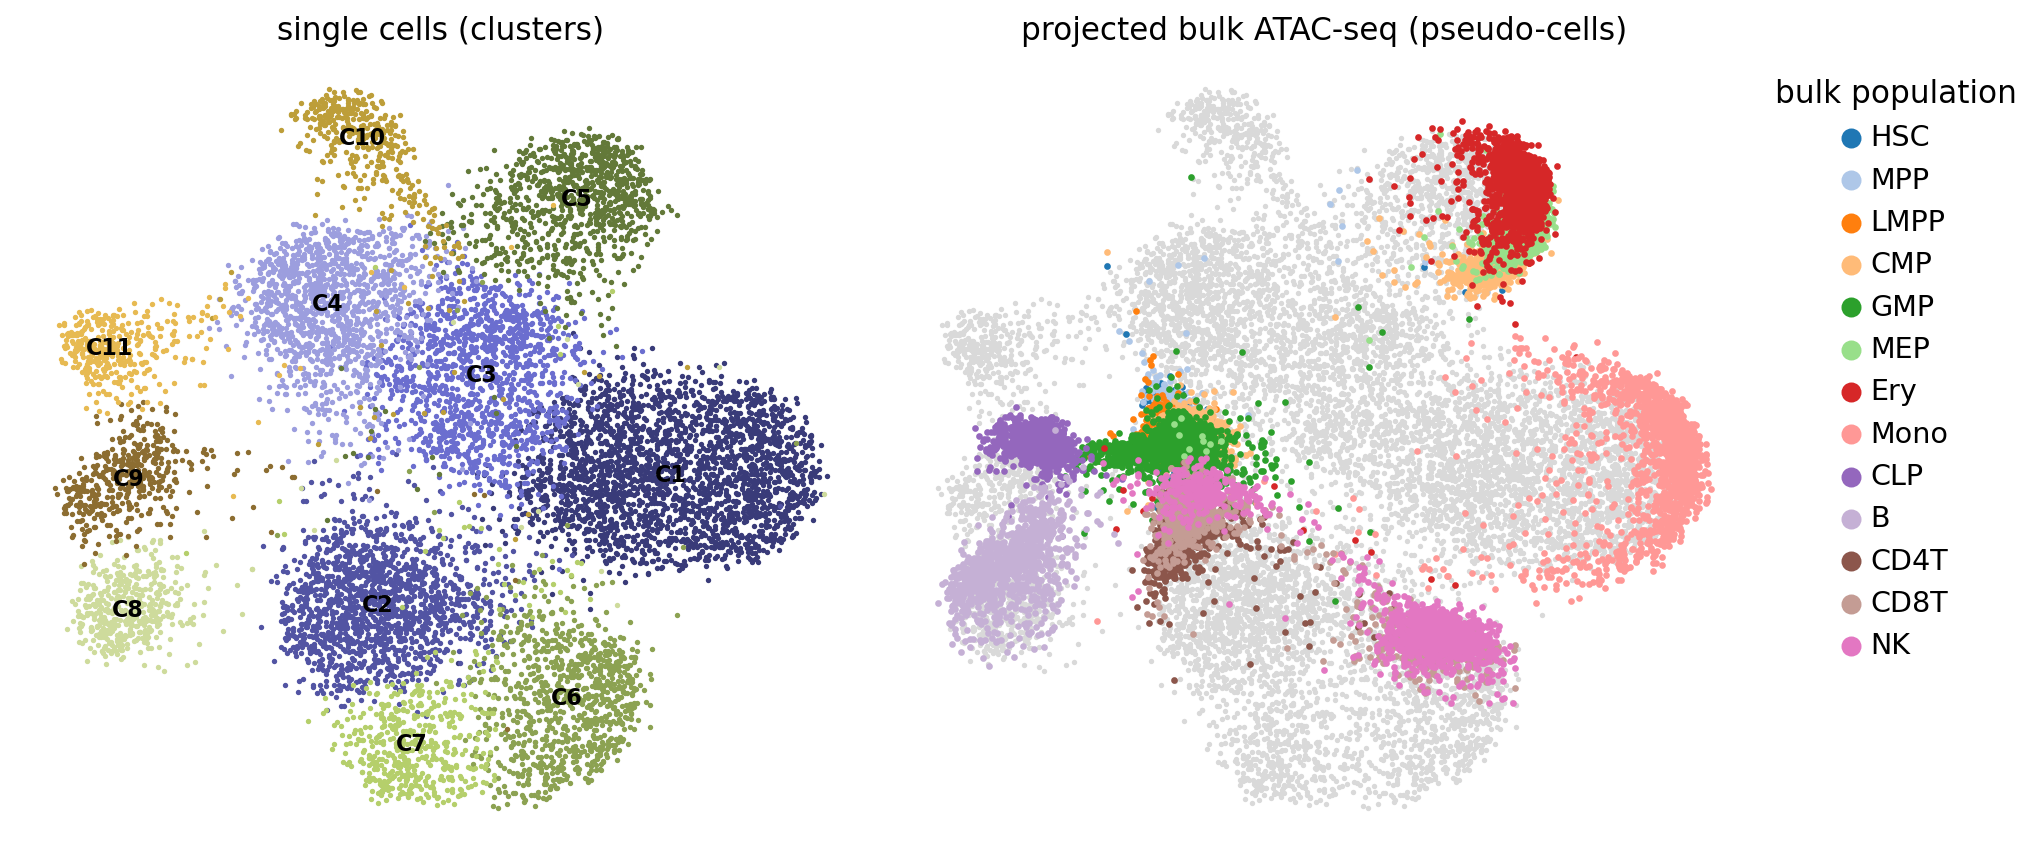

In [5]:
ref = proj.uns['reference_umap']
types = list(proj.obs['cell_type'].cat.categories)
cmap = plt.get_cmap('tab20')
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))

ax = axes[0]
clusters = tiles.obs['Clusters']
for i, c in enumerate(clusters.cat.categories):
    m = (clusters == c).to_numpy()
    ax.scatter(ref[m, 0], ref[m, 1], s=2, color=plt.get_cmap('tab20b')(i), rasterized=True)
    x, y = np.median(ref[m], axis=0)
    ax.text(x, y, c, fontsize=10, weight='bold', ha='center', va='center')
ax.set_title('single cells (clusters)'); ax.axis('off')

ax = axes[1]
ax.scatter(ref[:, 0], ref[:, 1], s=2, color='#d9d9d9', rasterized=True)
xy = proj.obsm['X_umap']
for i, t in enumerate(types):
    m = (proj.obs['cell_type'] == t).to_numpy()
    ax.scatter(xy[m, 0], xy[m, 1], s=4, color=cmap(i), label=t, rasterized=True)
ax.legend(markerscale=4, frameon=False, bbox_to_anchor=(1.0, 1.0), loc='upper left', title='bulk population')
ax.set_title('projected bulk ATAC-seq (pseudo-cells)'); ax.axis('off')
plt.tight_layout(); plt.show()

Points drawn later cover earlier ones in the overview, so each population gets its own panel below.

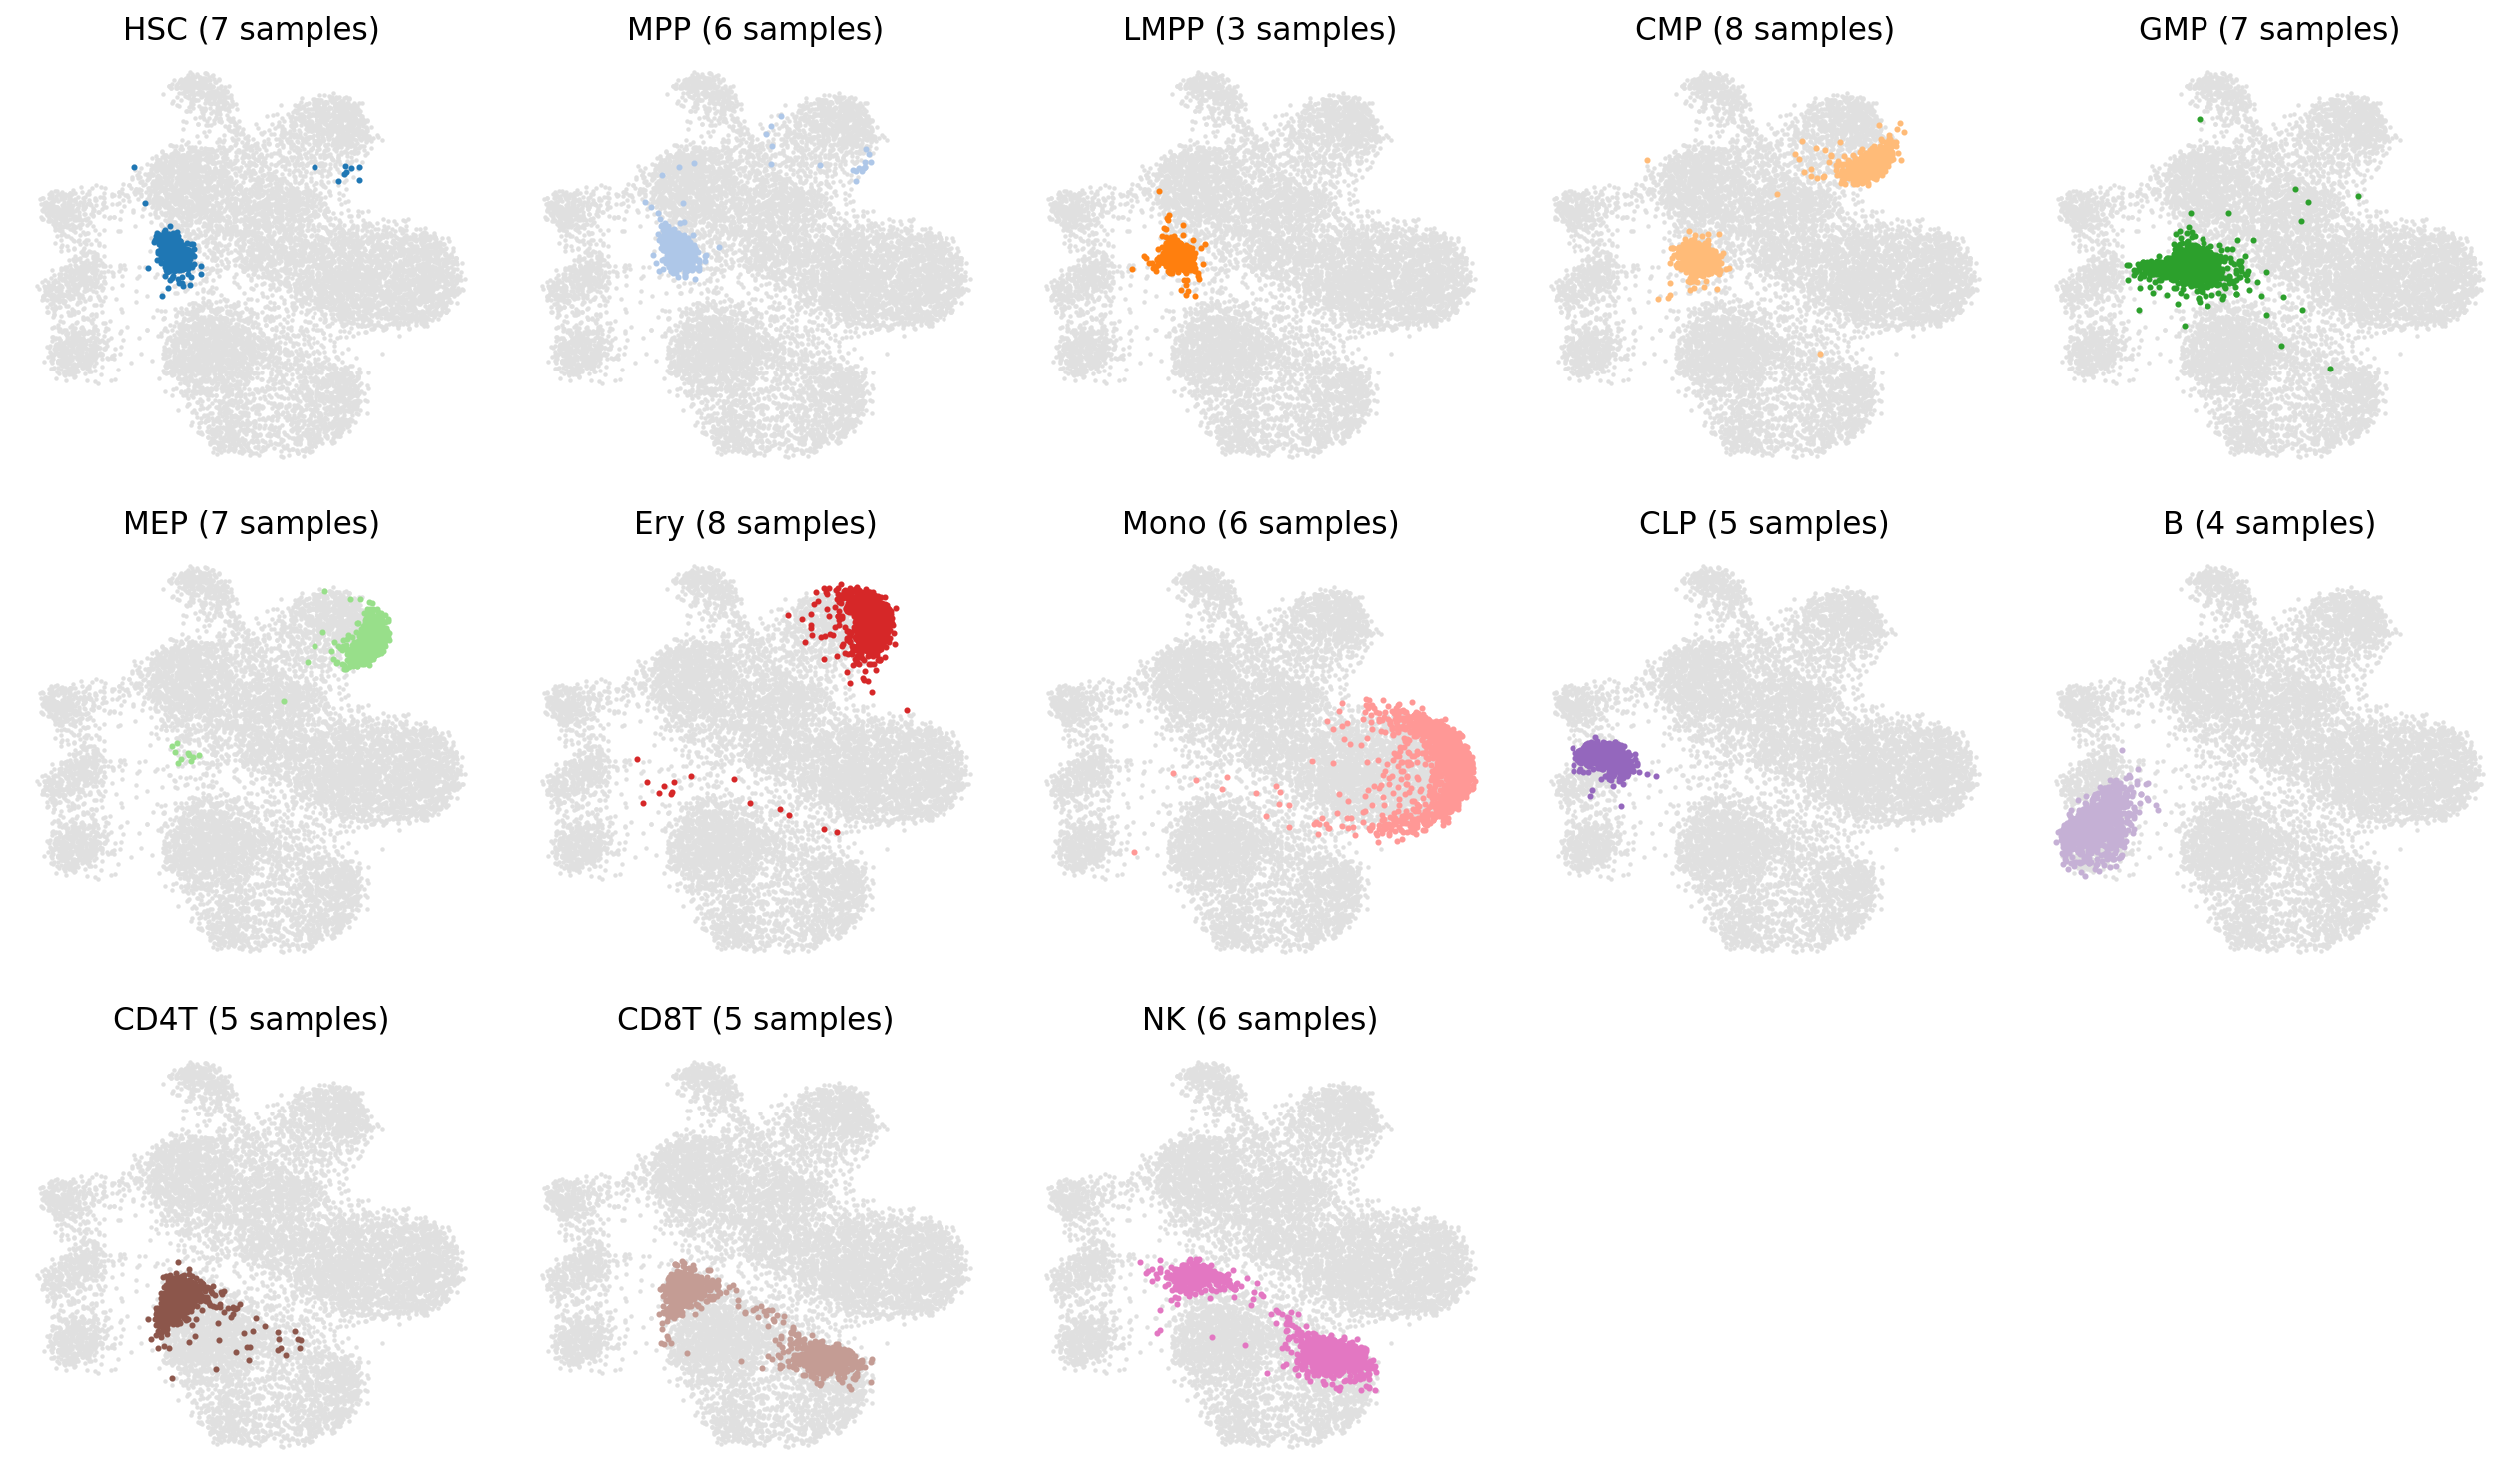

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9.5))
for ax, t in zip(axes.ravel(), types):
    m = (proj.obs['cell_type'] == t).to_numpy()
    ax.scatter(ref[:, 0], ref[:, 1], s=1, color='#e0e0e0', rasterized=True)
    ax.scatter(xy[m, 0], xy[m, 1], s=3, color=cmap(types.index(t)), rasterized=True)
    ax.set_title(f'{t} ({proj.obs.loc[m, "sample"].nunique()} samples)'); ax.axis('off')
for ax in axes.ravel()[len(types):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

The populations follow the lineage structure of the single cells. Monocytes, B cells, CD4 T cells, NK cells and the erythroid populations (MEP, erythroblasts) each land on one region, and CLPs sit next to the lymphoid progenitor clusters. HSC, MPP and LMPP pseudo-cells fall at the edge of the CD34+ progenitor region rather than inside it. A transformed UMAP position is an approximation, so the nearest neighbours in LSI space, summarised next, are the more reliable readout.

The table gives, for each population, the mean over its samples of the fraction of pseudo-cells whose 10 nearest single cells are mostly from each cluster.

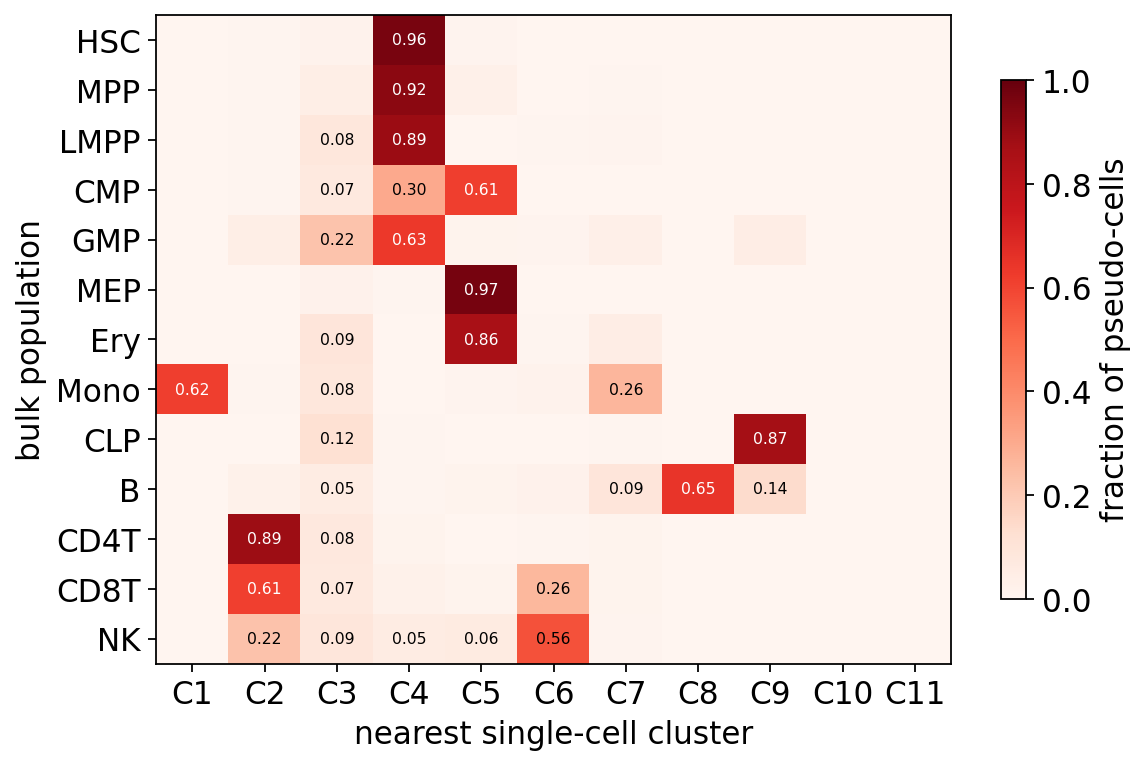

In [7]:
fr = proj.uns['group_fractions']
fr_type = fr.groupby(bulk.obs.loc[fr.index, 'cell_type'].to_numpy(), observed=True).mean().reindex(types)

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(fr_type.to_numpy(), cmap='Reds', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(fr_type.shape[1]), fr_type.columns)
ax.set_yticks(range(fr_type.shape[0]), fr_type.index)
for i in range(fr_type.shape[0]):
    for j in range(fr_type.shape[1]):
        v = fr_type.iat[i, j]
        if v >= 0.05:
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if v > 0.6 else 'black')
ax.set_xlabel('nearest single-cell cluster'); ax.set_ylabel('bulk population')
plt.colorbar(im, ax=ax, label='fraction of pseudo-cells', shrink=0.8)
plt.tight_layout(); plt.show()

## Deconvolution

`deconvolve_bulk` explains each bulk profile as a non-negative mixture of cluster pseudobulk profiles. It uses the 5,000 peaks whose accessibility varies most across clusters, and with `weight='cells'` converts read weights into cell proportions. Here the single-cell side is the peak matrix of the same data. Sorted populations should come out as nearly pure. A population with no matching cluster has to be explained by a mixture, which shows up as a lower `residual_r2`.

In [8]:
%%time
peaks = ad.read_h5ad(DATA / 'heme_peaks.h5ad')
est = epi.tl.deconvolve_bulk(peaks, bulk, 'Clusters', weight='cells')
est_type = est.groupby(bulk.obs.loc[est.index, 'cell_type'].to_numpy(), observed=True).mean().reindex(types)
est_type.round(2)

CPU times: user 5.09 s, sys: 1.02 s, total: 6.11 s
Wall time: 9.2 s


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,residual_r2
HSC,0.00,0.01,0.00,0.78,0.21,0.00,0.00,0.00,0.00,0.00,0.00,0.46
MPP,0.00,0.01,0.00,0.64,0.35,0.00,0.00,0.00,0.00,0.00,0.00,0.49
LMPP,0.00,0.03,0.05,0.70,0.00,0.00,0.00,0.00,0.01,0.18,0.03,0.50
CMP,0.00,0.01,0.14,0.20,0.64,0.00,0.00,0.00,0.00,0.00,0.00,0.53
GMP,0.00,0.01,0.47,0.30,0.00,0.00,0.00,0.00,0.04,0.13,0.04,0.52
MEP,0.00,0.00,0.00,0.00,0.98,0.00,0.01,0.00,0.00,0.00,0.00,0.61
Ery,0.00,0.00,0.00,0.00,0.93,0.00,0.03,0.00,0.03,0.00,0.00,0.23
Mono,0.88,0.00,0.07,0.00,0.01,0.00,0.00,0.01,0.01,0.01,0.00,0.77
CLP,0.00,0.03,0.00,0.00,0.00,0.00,0.00,0.01,0.36,0.00,0.60,0.46
B,0.01,0.00,0.01,0.00,0.01,0.00,0.00,0.89,0.05,0.02,0.00,0.67


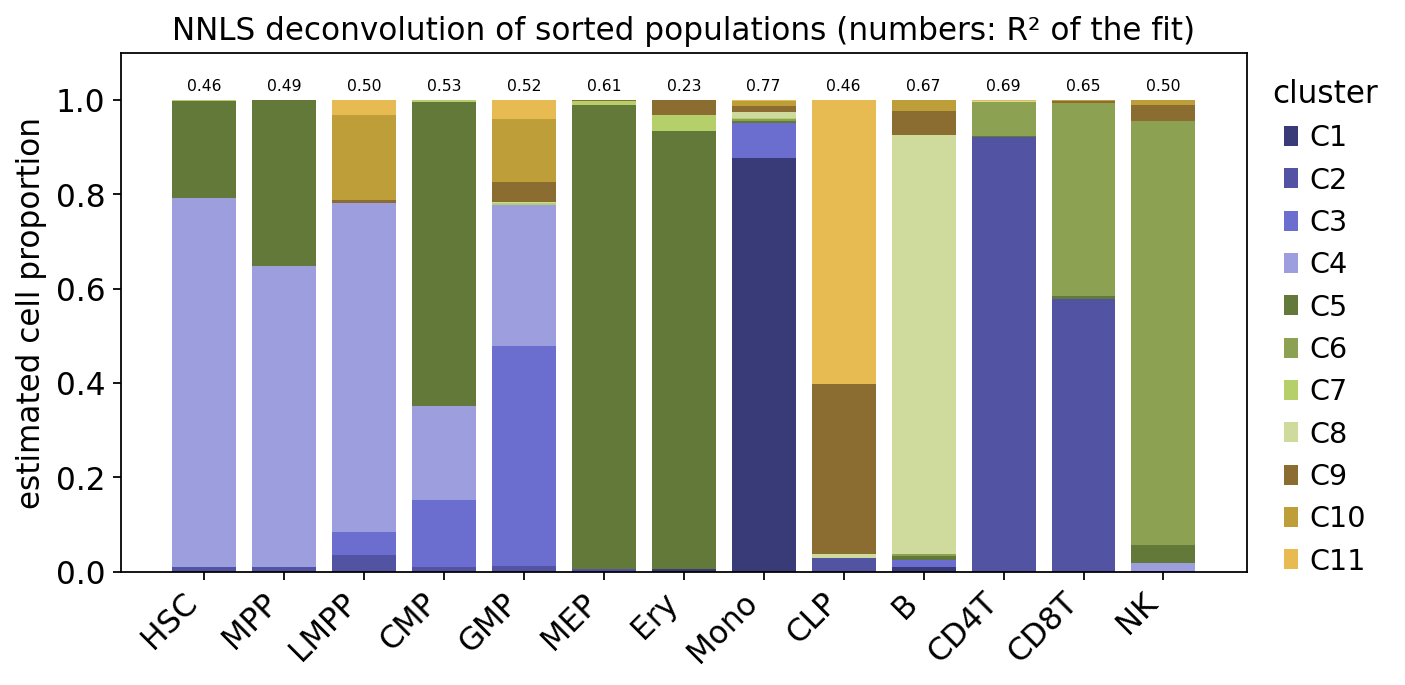

In [9]:
comp = est_type.drop(columns='residual_r2')
fig, ax = plt.subplots(figsize=(9, 4.5))
bottom = np.zeros(len(comp))
for j, c in enumerate(comp.columns):
    ax.bar(comp.index, comp[c], bottom=bottom, color=plt.get_cmap('tab20b')(j), label=c)
    bottom += comp[c].to_numpy()
for i, r2 in enumerate(est_type['residual_r2']):
    ax.text(i, 1.02, f'{r2:.2f}', ha='center', fontsize=7)
ax.set_ylim(0, 1.1); ax.set_ylabel('estimated cell proportion')
ax.set_title('NNLS deconvolution of sorted populations (numbers: R² of the fit)')
ax.legend(ncol=1, frameon=False, bbox_to_anchor=(1.0, 1.0), loc='upper left', title='cluster')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

The two readouts agree:
- **Mature populations.** Monocytes (C1), B cells (C8), CD4 T cells (C2) and NK cells (C6) are mostly assigned to one cluster each. CD8 T cells split between the T-cell cluster C2 and the NK/CD8 cluster C6.
- **Early progenitors.** HSC, MPP and LMPP are mostly C4, the HSC/early-progenitor cluster. CMP and GMP spread over C3, C4 and C5, because the single-cell clusters do not separate them as sharply as cell sorting does.
- **Fit quality.** It varies by population. Monocytes, B and T cells fit best (R² 0.65–0.77). Erythroblasts fit worst (R² 0.23): their closest cluster, C5, is an erythroid *progenitor* cluster, and no single-cell cluster is as mature as sorted erythroblasts.

## Reproducing ArchR exactly

By default the pseudo-cells are drawn with numpy's multinomial sampler, which has the same distribution as ArchR's sampling. With `rng='archr'` Epione instead reproduces R's Mersenne-Twister and `sample()` draws, including the re-seeding inside ArchR's `.projectLSI`. Given ArchR's LSI model as an `epi.tl.LSIModel(flavor='archr', ...)`, the projected coordinates are then identical to `projectBulkATAC`'s output after `set.seed(seed)`.

Validation against ArchR 1.0.3 on its own hematopoiesis project and these 77 bulk samples (`tests/parity/bulk_projection/MANIFEST.md`):

| check | result |
|---|---|
| feature mapping (25,000 features × 77 samples) | identical |
| LSI projection of identical pseudo-cells | max difference 2e-14 |
| `rng='archr'`, all 19,250 pseudo-cells end to end | identical (max difference 2e-14) |
| `rng='numpy'`: majority nearest cluster per sample | 77/77 agree; mean cluster-fraction TVD 0.007 |
| UMAP (umap-learn vs uwot): nearest cluster per pseudo-cell | 98.5% agree; per-sample majority 77/77 |
| deconvolution, 50 synthetic mixtures with known proportions | Pearson 0.96, mean absolute error 0.017 |